# Experiment 5: targeted hard-error training

This experiment tests a stronger targeted-training strategy than margin weighting alone. It uses combined word and character TF-IDF features, identifies hard **incorrect** examples with out-of-fold predictions, and compares weighting and oversampling against matched random controls.

An example is targeted only when it is both uncertain and misclassified. This avoids giving extra emphasis to uncertain examples that the model already classifies correctly.

## Imports

In [1]:
import os
import pickle
import sys

import numpy as np
import pandas as pd
from scipy.sparse import vstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold

sys.path.append("..")
from utils.preprocessing import LABELS, clean_text, encode_labels

np.random.seed(42)


## Load and preprocess the data

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

features = FeatureUnion([
    ("word", TfidfVectorizer(
        preprocessor=clean_text,
        tokenizer=str.split,
        token_pattern=None,
        ngram_range=(1, 2),
        sublinear_tf=True,
    )),
    ("char", TfidfVectorizer(
        preprocessor=clean_text,
        analyzer="char_wb",
        ngram_range=(3, 5),
        sublinear_tf=True,
    )),
])

X_train = features.fit_transform(train_df.sentence)
X_val = features.transform(val_df.sentence)
X_test = features.transform(test_df.sentence)

print(X_train.shape, X_val.shape, X_test.shape)


(2901, 81612) (967, 81612) (968, 81612)


## Train the baseline and generate out-of-fold predictions

Out-of-fold predictions ensure that each training example is evaluated by a model that did not train on it. The targeted subset contains examples with margin at most `0.2` that are also misclassified.

In [3]:
def train_model(X, y, sample_weight=None):
    model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
    model.fit(X, y, sample_weight=sample_weight)
    return model

def margins(probabilities):
    top_two = np.partition(probabilities, -2, axis=1)[:, -2:]
    return top_two.max(axis=1) - top_two.min(axis=1)

def score(model, X, y, is_hard):
    predictions = model.predict(X)
    return {
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "hard_accuracy": accuracy_score(y[is_hard], predictions[is_hard]),
        "hard_f1": f1_score(y[is_hard], predictions[is_hard], average="macro"),
        "easy_accuracy": accuracy_score(y[~is_hard], predictions[~is_hard]),
        "easy_f1": f1_score(y[~is_hard], predictions[~is_hard], average="macro"),
    }

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = np.zeros((len(y_train), len(LABELS)))
oof_predictions = np.zeros(len(y_train), dtype=int)

for fold_train, fold_held_out in folds.split(X_train, y_train):
    fold_model = train_model(X_train[fold_train], y_train[fold_train])
    oof_probabilities[fold_held_out] = fold_model.predict_proba(X_train[fold_held_out])
    oof_predictions[fold_held_out] = fold_model.predict(X_train[fold_held_out])

baseline_model = train_model(X_train, y_train)
val_probabilities = baseline_model.predict_proba(X_val)
test_probabilities = baseline_model.predict_proba(X_test)

train_is_hard = (margins(oof_probabilities) <= 0.2) & (oof_predictions != y_train)
val_is_hard = margins(val_probabilities) <= 0.2
test_is_hard = margins(test_probabilities) <= 0.2

print("Hard incorrect training examples:", train_is_hard.sum())
print("Hard validation examples:", val_is_hard.sum())
print("Hard test examples:", test_is_hard.sum())


Hard incorrect training examples: 164
Hard validation examples: 111
Hard test examples: 101


## Train targeted and random-control models

The experiment compares four conditions:

- Baseline
- Hard-error weighting
- Hard-error oversampling
- Random oversampling with the same number of examples

The validation hard subset is fixed using the baseline predictions.

In [4]:
target_indices = np.flatnonzero(train_is_hard)

hard_weights = np.where(train_is_hard, 3.0, 1.0)
hard_weight_model = train_model(X_train, y_train, hard_weights)

X_hard = vstack([X_train, X_train[target_indices], X_train[target_indices]])
y_hard = np.concatenate([y_train, y_train[target_indices], y_train[target_indices]])
hard_oversample_model = train_model(X_hard, y_hard)

random_indices = np.random.default_rng(42).choice(
    len(y_train), size=len(target_indices), replace=False
)
X_random = vstack([X_train, X_train[random_indices], X_train[random_indices]])
y_random = np.concatenate([y_train, y_train[random_indices], y_train[random_indices]])
random_oversample_model = train_model(X_random, y_random)

models = {
    "baseline": baseline_model,
    "hard_weight": hard_weight_model,
    "hard_oversample": hard_oversample_model,
    "random_oversample": random_oversample_model,
}

validation_results = pd.DataFrame([
    {"condition": name, **score(model, X_val, y_val, val_is_hard)}
    for name, model in models.items()
])
validation_results


,condition,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1
0,baseline,0.782834,0.736717,0.504505,0.492052,0.818925,0.771824
1,hard_weight,0.778697,0.729925,0.468468,0.437988,0.818925,0.771824
2,hard_oversample,0.778697,0.729925,0.468468,0.437988,0.818925,0.771824
3,random_oversample,0.780765,0.732171,0.486486,0.461540,0.818925,0.771824


## Select the targeted condition

The targeted condition is selected using validation hard-subset macro-F1. The baseline remains selected if neither targeted method improves over it.

In [5]:
best_targeted = validation_results[
    validation_results.condition.isin(["hard_weight", "hard_oversample"])
].sort_values("hard_f1", ascending=False).iloc[0]
baseline_validation = validation_results[
    validation_results.condition == "baseline"
].iloc[0]

best_condition = (
    best_targeted.condition
    if best_targeted.hard_f1 > baseline_validation.hard_f1
    else "baseline"
)
print("Selected condition:", best_condition)


Selected condition: baseline


## Final test evaluation

The test hard subset is fixed using the baseline's out-of-sample predictions: an example is hard when it is uncertain. Labels are used only to calculate metrics and TP/FN, not to define the test subset.


baseline
              precision    recall  f1-score   support

    negative       0.75      0.68      0.71       121
     neutral       0.82      0.87      0.84       575
    positive       0.73      0.67      0.70       272

    accuracy                           0.79       968
   macro avg       0.76      0.74      0.75       968
weighted avg       0.78      0.79      0.78       968

Hard negative: TP=7, FN=10
Hard neutral: TP=29, FN=22
Hard positive: TP=15, FN=18

hard_weight
              precision    recall  f1-score   support

    negative       0.76      0.64      0.70       121
     neutral       0.81      0.87      0.84       575
    positive       0.73      0.67      0.70       272

    accuracy                           0.79       968
   macro avg       0.77      0.73      0.75       968
weighted avg       0.78      0.79      0.78       968

Hard negative: TP=3, FN=14
Hard neutral: TP=33, FN=18
Hard positive: TP=16, FN=17

hard_oversample
              precision    recall 

,condition,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1
0,baseline,0.786157,0.748872,0.504950,0.480632,0.818916,0.785255
1,hard_weight,0.787190,0.746620,0.514851,0.438698,0.818916,0.785255
2,hard_oversample,0.787190,0.746620,0.514851,0.438698,0.818916,0.785255
3,random_oversample,0.785124,0.748686,0.495050,0.478826,0.818916,0.784254


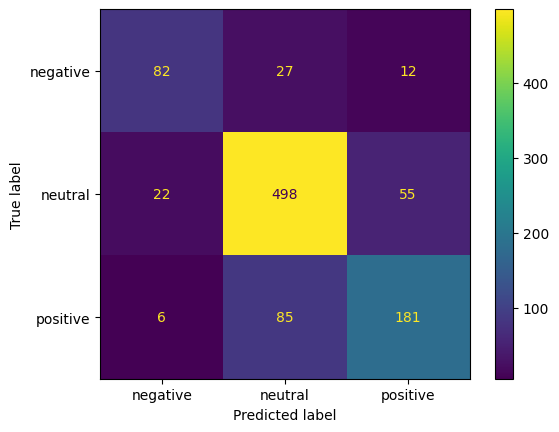

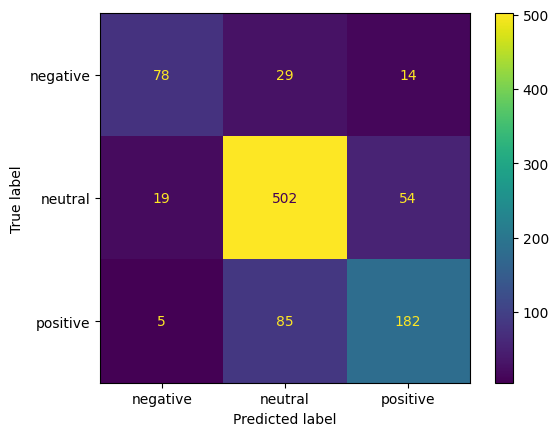

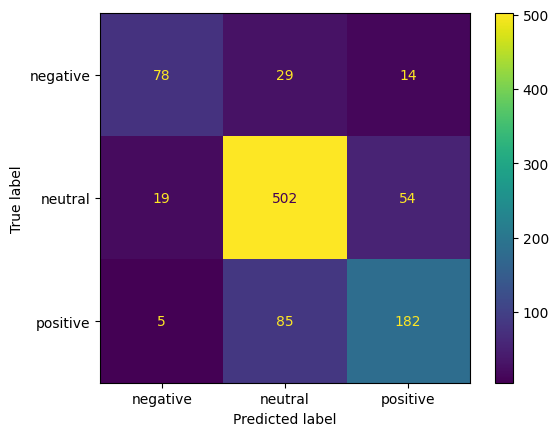

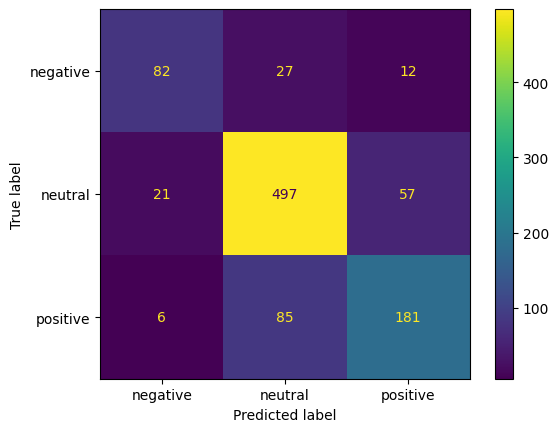

In [6]:
test_results = []
for name in ["baseline", "hard_weight", "hard_oversample", "random_oversample"]:
    model = models[name]
    predictions = model.predict(X_test)
    test_results.append({"condition": name, **score(model, X_test, y_test, test_is_hard)})

    hard_true = y_test[test_is_hard]
    hard_pred = predictions[test_is_hard]
    print("\n" + name)
    print(classification_report(y_test, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=LABELS)

    for class_id, label in enumerate(LABELS):
        tp = ((hard_true == class_id) & (hard_pred == class_id)).sum()
        fn = ((hard_true == class_id) & (hard_pred != class_id)).sum()
        print(f"Hard {label}: TP={tp}, FN={fn}")

test_results = pd.DataFrame(test_results)
test_results


## Save results

In [ ]:
# os.makedirs("../models", exist_ok=True)

# validation_results.to_csv("../results/experiment_5_validation.csv", index=False)
# test_results.to_csv("../results/experiment_5_test.csv", index=False)

# train_df["is_hard"] = train_is_hard
# val_df["is_hard"] = val_is_hard
# test_df["is_hard"] = test_is_hard
# train_df.to_csv("../results/experiment_5_train_with_hard.csv", index=False)
# val_df.to_csv("../results/experiment_5_val_with_hard.csv", index=False)
# test_df.to_csv("../results/experiment_5_test_with_hard.csv", index=False)

# with open("../models/experiment_5_tfidf_features.pkl", "wb") as f:
#     pickle.dump(features, f)
# with open("../models/experiment_5_baseline_logreg.pkl", "wb") as f:
#     pickle.dump(baseline_model, f)
# with open("../models/experiment_5_selected_logreg.pkl", "wb") as f:
#     pickle.dump(models[best_condition], f)
